In [1]:
from sklearn import datasets
import pandas as pd

df = datasets.load_diabetes()


In [ ]:
X = df.data
y = (df.target >  140).astype(int)
dff = pd.DataFrame(data=X , columns=df.feature_names)
dff["diabetes"] = y
dff.head(20)



,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,diabetes
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,1
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,1
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,1
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,0
5,-0.092695,-0.044642,-0.040696,-0.019442,-0.068991,-0.079288,0.041277,-0.076395,-0.041176,-0.096346,0
6,-0.045472,0.050680,-0.047163,-0.015999,-0.040096,-0.024800,0.000779,-0.039493,-0.062917,-0.038357,0
7,0.063504,0.050680,-0.001895,0.066629,0.090620,0.108914,0.022869,0.017703,-0.035816,0.003064,0
8,0.041708,0.050680,0.061696,-0.040099,-0.013953,0.006202,-0.028674,-0.002592,-0.014960,0.011349,0
9,-0.070900,-0.044642,0.039062,-0.033213,-0.012577,-0.034508,-0.024993,-0.002592,0.067737,-0.013504,1


Accuracy: 0.7303370786516854

Classification Report
              precision    recall  f1-score   support

           0       0.78      0.71      0.74        49
           1       0.68      0.75      0.71        40

    accuracy                           0.73        89
   macro avg       0.73      0.73      0.73        89
weighted avg       0.73      0.73      0.73        89



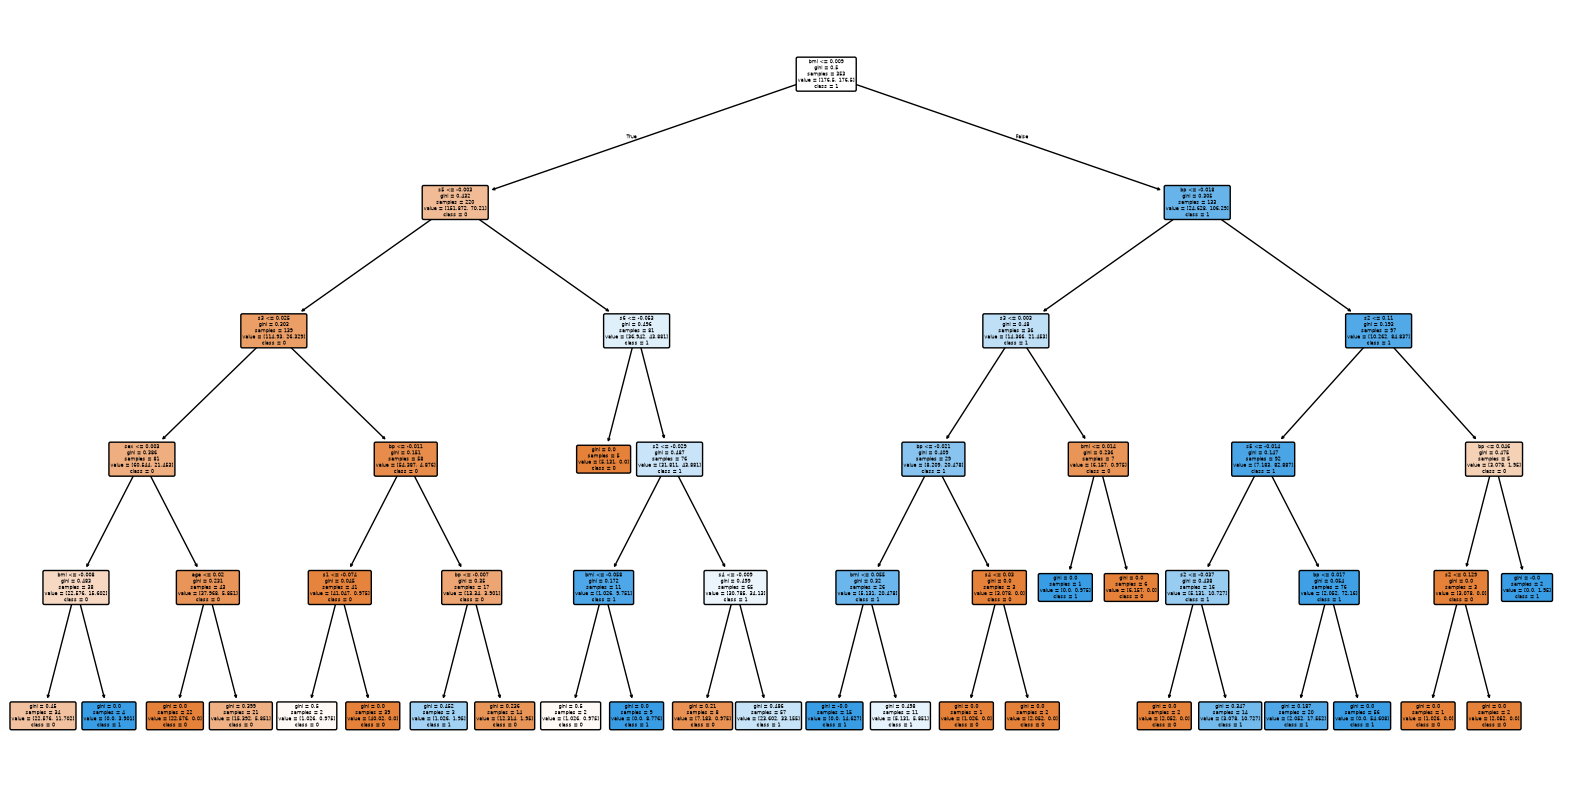

In [8]:
# DTree Model

# Decision Tree Classifier Template

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from sklearn.preprocessing import LabelEncoder


# df = pd.read_csv("Credit.csv")
# X = df.drop(['HireDate', 'EducationField', 'BusinessTravel', 'OverTime', 'Attrition', 'Gender', 'Over18', 'ManagerComments', 'Department', 'MaritalStatus', 'JobRole'], axis=1)   # Features
# X = df[["YearsAtCompany" , "WorkLifeBalance" , "JobSatisfaction"]]
# sd = StandardScaler()
# df[["RevolvingUtiOfUnsecuredLines" , "DebtRatio"]] = sd.fit_transform(df[["RevolvingUtiOfUnsecuredLines" , "DebtRatio"]])

# label = LabelEncoder()
# df["OverTime"] = label.fit_transform(df["OverTime"])
# df["JobRole"] = label.fit_transform(df["JobRole"])
# df["MaritalStatus"] = label.fit_transform(df["MaritalStatus"])

# feature_cols = [
#     'OverTime', 'MonthlyIncome', 'TotalWorkingYears', 'Age', 
#     'YearsAtCompany', 'YearsWithCurrManager', 'JobRole', 'JobLevel', 
#     'StockOptionLevel', 'DistanceFromHome', 'JobSatisfaction', 
#     'EnvironmentSatisfaction', 'MaritalStatus', 'YearsInCurrentRole',
#     'NumCompaniesWorked', 'PercentSalaryHike', 'WorkLifeBalance', 
#     'TrainingTimesLastYear', 'YearsSinceLastPromotion', 'Education'
# ]    


X = dff.drop("diabetes",axis=1)
y = dff["diabetes"]                # Label


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

model = DecisionTreeClassifier(
    criterion="gini",   # or "entropy"
    max_depth=5,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# print("R2 score is " , r2_score(y_test , y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report")

print(classification_report(y_test, y_pred))

plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=[str(c) for c in model.classes_],
    filled=True,
    rounded=True
)

plt.show()

In [14]:
# KNN


import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# =========================
# Load Dataset
# =========================

# df = pd.read_excel("Credit3.xls")
# scaler = StandardScaler()

# df[["RevolvingUtiOfUnsecuredLines", "DebtRatio"]] = scaler.fit_transform(
#     df[["RevolvingUtiOfUnsecuredLines", "DebtRatio"]]
# )

# =========================
# Feature Selection
# =========================

# Option 1: Use all features except target
X = dff.drop("diabetes", axis=1)

# Option 2: Use selected features
# X = df[[
#     "Age",
#     "DebtRatio",
#     "MonthlyIncome",
#     "NumberOfOpenCreditLinesAndLoans"
# ]]

y = dff["diabetes"]

# =========================
# Train Test Split
# =========================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
    # stratify=y
)

# =========================
# Feature Scaling
# =========================

# IMPORTANT FOR KNN
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# =========================
# Create KNN Model
# =========================

model = KNeighborsClassifier(
    n_neighbors=10,
    weights='uniform',      # or 'distance'
    metric='euclidean'      # or 'manhattan'
)

# =========================
# Train Model
# =========================

model.fit(X_train, y_train)

# =========================
# Prediction
# =========================

y_pred = model.predict(X_test)

# =========================
# Evaluation
# =========================

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report\n")
print(classification_report(y_test, y_pred))

Accuracy: 0.7293233082706767

Classification Report

              precision    recall  f1-score   support

           0       0.74      0.78      0.76        72
           1       0.72      0.67      0.69        61

    accuracy                           0.73       133
   macro avg       0.73      0.72      0.73       133
weighted avg       0.73      0.73      0.73       133

